# Lens 2 — Notebook 08: Product-Demand Validation, Stacking & Model Selection
**IT3091 Machine Learning — Industry Explorer Track**  
**Group ID:** `2026-AI-36` | **Primary Author:** `IT24102664`  
**Lens:** 2 — Product-Demand Forecasting  
**Role:** Product-Demand Validation, Stacking & Model Selection

---

## Notebook Purpose
This notebook performs:
1. **Walk-forward cross-validation** to robustly assess model stability
2. **Stacking ensemble** with Ridge + RF + LightGBM as base learners
3. **Definitive champion selection** for Lens 2 using validation WAPE
4. **Kitchen Risk Buffer** — asymmetric safety margin for stockout prevention
5. **Business impact analysis** — waste savings and stockout rate reduction
6. **Final recommendations** for kitchen operations

---

## Section Overview
1. Environment Setup
2. Walk-Forward Cross-Validation
3. Stacking Ensemble Architecture
4. Final Champion Selection
5. Definitive Test-Set Evaluation
6. Kitchen Risk Buffer
7. Per-Item Final Evaluation & Kitchen Recommendations
8. Business Impact Analysis
9. Model Serialisation
10. Limitations & Responsible AI Declaration

In [1]:
import os, sys, warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit, KFold
import lightgbm as lgb
import xgboost as xgb
import joblib

warnings.filterwarnings('ignore')
np.random.seed(42)

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['font.size'] = 11

print("Environment initialised.")

Environment initialised.


In [2]:
FEAT_PATH = '../data/processed/demand_feature_matrix.csv'
META_PATH = '../data/processed/demand_feature_meta.json'

df = pd.read_csv(FEAT_PATH, parse_dates=['Date'])
df = df.sort_values(['Date', 'ItemName']).reset_index(drop=True)

with open(META_PATH) as f:
    meta = json.load(f)

FEATURE_COLS = meta['feature_cols']
TARGET_COL   = meta['target_col']
CORE_ITEMS   = meta['items']

unique_dates  = sorted(df['Date'].unique())
n_dates       = len(unique_dates)
n_train_dates = int(n_dates * 0.70)
n_val_dates   = int(n_dates * 0.15)

train_dates = unique_dates[:n_train_dates]
val_dates   = unique_dates[n_train_dates:n_train_dates + n_val_dates]
test_dates  = unique_dates[n_train_dates + n_val_dates:]

train_df = df[df['Date'].isin(train_dates)].reset_index(drop=True)
val_df   = df[df['Date'].isin(val_dates)].reset_index(drop=True)
test_df  = df[df['Date'].isin(test_dates)].reset_index(drop=True)

X_train, y_train = train_df[FEATURE_COLS], train_df[TARGET_COL]
X_val,   y_val   = val_df[FEATURE_COLS],   val_df[TARGET_COL]
X_test,  y_test  = test_df[FEATURE_COLS],  test_df[TARGET_COL]

print(f"Train: {len(train_df):,} | Val: {len(val_df):,} | Test: {len(test_df):,}")

def compute_metrics(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.maximum(np.array(y_pred), 0.0)
    mae  = np.mean(np.abs(y_true - y_pred))
    rmse = np.sqrt(np.mean((y_true - y_pred)**2))
    wape = np.sum(np.abs(y_true - y_pred)) / max(np.sum(np.abs(y_true)), 1e-6) * 100
    ss_res = np.sum((y_true - y_pred)**2)
    ss_tot = np.sum((y_true - np.mean(y_true))**2)
    r2 = 1 - ss_res/ss_tot if ss_tot > 0 else 0.0
    return {'MAE': round(mae,2), 'RMSE': round(rmse,2), 'WAPE_pct': round(wape,2), 'R2': round(r2,4)}

def per_item_wape(df_eval, pred_col):
    results = []
    for item in CORE_ITEMS:
        sub = df_eval[df_eval['ItemName'] == item]
        if len(sub) == 0: continue
        y_t = sub['Qty'].values
        y_p = np.maximum(sub[pred_col].values, 0)
        wape = np.sum(np.abs(y_t-y_p)) / max(np.sum(np.abs(y_t)), 1e-6) * 100
        mae  = np.mean(np.abs(y_t-y_p))
        results.append({'Item': item, 'WAPE (%)': round(wape, 2), 'MAE (portions)': round(mae, 2)})
    return pd.DataFrame(results).sort_values('WAPE (%)')

print("Helper functions defined.")

Train: 6,721 | Val: 1,441 | Test: 1,452
Helper functions defined.


---
## 2. Walk-Forward Cross-Validation

We use `TimeSeriesSplit` on the training set to produce 5 expanding folds. This gives a realistic estimate of how each model performs on unseen future data.

In [3]:
# Use date-grouped splits (all items for a date stay together)
train_unique_dates = sorted(train_df['Date'].unique())
n_splits = 5
fold_size = len(train_unique_dates) // (n_splits + 1)

cv_results = {m: [] for m in ['Ridge', 'RF', 'LightGBM', 'XGBoost']}

for fold in range(n_splits):
    n_train_fold = fold_size * (fold + 1)
    n_val_fold   = min(fold_size, len(train_unique_dates) - n_train_fold)
    
    tr_dates = train_unique_dates[:n_train_fold]
    va_dates = train_unique_dates[n_train_fold:n_train_fold + n_val_fold]
    
    if len(va_dates) == 0:
        continue
    
    tr = train_df[train_df['Date'].isin(tr_dates)]
    va = train_df[train_df['Date'].isin(va_dates)]
    Xtr, ytr = tr[FEATURE_COLS], tr[TARGET_COL]
    Xva, yva = va[FEATURE_COLS], va[TARGET_COL]
    
    # Ridge
    p = Pipeline([('sc', StandardScaler()), ('m', Ridge(alpha=100))])
    p.fit(Xtr, ytr)
    cv_results['Ridge'].append(compute_metrics(yva, p.predict(Xva))['WAPE_pct'])
    
    # RF
    rf = RandomForestRegressor(n_estimators=100, min_samples_leaf=5, random_state=42, n_jobs=-1)
    rf.fit(Xtr, ytr)
    cv_results['RF'].append(compute_metrics(yva, rf.predict(Xva))['WAPE_pct'])
    
    # LightGBM
    lg = lgb.LGBMRegressor(n_estimators=200, learning_rate=0.05, max_depth=7, random_state=42, verbosity=-1)
    lg.fit(Xtr, ytr)
    cv_results['LightGBM'].append(compute_metrics(yva, lg.predict(Xva))['WAPE_pct'])
    
    # XGBoost
    xgbm = xgb.XGBRegressor(n_estimators=200, learning_rate=0.05, max_depth=7, random_state=42, verbosity=0)
    xgbm.fit(Xtr, ytr)
    cv_results['XGBoost'].append(compute_metrics(yva, xgbm.predict(Xva))['WAPE_pct'])
    
    print(f"Fold {fold+1}: done ({len(tr_dates)} train / {len(va_dates)} val days)")

cv_df = pd.DataFrame({m: cv_results[m] for m in cv_results if len(cv_results[m]) > 0})
cv_df.index = [f'Fold {i+1}' for i in range(len(cv_df))]
cv_df.loc['Mean'] = cv_df.mean()
cv_df.loc['Std']  = cv_df.std()

print("\nWalk-Forward CV WAPE (%):")
print(cv_df.round(2))

Fold 1: done (101 train / 101 val days)


Fold 2: done (202 train / 101 val days)


Fold 3: done (303 train / 101 val days)


Fold 4: done (404 train / 101 val days)


Fold 5: done (505 train / 101 val days)

Walk-Forward CV WAPE (%):
        Ridge     RF  LightGBM  XGBoost
Fold 1  51.82  53.91     55.04    56.83
Fold 2  51.42  55.43     55.69    60.09
Fold 3  55.09  58.78     67.94    67.52
Fold 4  47.94  49.54     50.29    53.96
Fold 5  55.55  57.89     58.03    65.19
Mean    52.36  55.11     57.40    60.72
Std      2.77   3.28      5.84     5.05


---
## 3. Stacking Ensemble Architecture

In [4]:
base_estimators = [
    ('ridge', Pipeline([('sc', StandardScaler()), ('m', Ridge(alpha=100))])),
    ('rf',    RandomForestRegressor(n_estimators=150, min_samples_leaf=5,
                                    max_features='sqrt', random_state=42, n_jobs=-1)),
    ('lgbm',  lgb.LGBMRegressor(n_estimators=200, learning_rate=0.05,
                                 max_depth=7, random_state=42, verbosity=-1)),
]
meta_learner = Pipeline([('sc', StandardScaler()), ('m', Ridge(alpha=10))])

stacking_model = StackingRegressor(
    estimators=base_estimators,
    final_estimator=meta_learner,
    cv=KFold(n_splits=5, shuffle=False),
    passthrough=False,
    n_jobs=-1
)

print("Fitting Stacking Ensemble (Lens 2)...")
stacking_model.fit(X_train, y_train)
print("Done.")

val_pred_stack  = np.maximum(stacking_model.predict(X_val),  0)
test_pred_stack = np.maximum(stacking_model.predict(X_test), 0)

vm_stack = compute_metrics(y_val, val_pred_stack)
tm_stack = compute_metrics(y_test, test_pred_stack)

print(f"\nStacking: Val WAPE={vm_stack['WAPE_pct']:.2f}%  |  Test WAPE={tm_stack['WAPE_pct']:.2f}%")

Fitting Stacking Ensemble (Lens 2)...


Done.



Stacking: Val WAPE=54.60%  |  Test WAPE=53.68%


---
## 4. Final Champion Selection

In [5]:
# Train all models on full training set for final comparison
ridge_model = Pipeline([('sc', StandardScaler()), ('m', Ridge(alpha=100))])
ridge_model.fit(X_train, y_train)
val_pred_ridge  = np.maximum(ridge_model.predict(X_val),  0)
test_pred_ridge = np.maximum(ridge_model.predict(X_test), 0)

rf_model = RandomForestRegressor(n_estimators=200, min_samples_leaf=5,
                                 max_features='sqrt', random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
val_pred_rf  = np.maximum(rf_model.predict(X_val),  0)
test_pred_rf = np.maximum(rf_model.predict(X_test), 0)

lgbm_model = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.05, max_depth=7,
                                random_state=42, verbosity=-1)
lgbm_model.fit(X_train, y_train,
               eval_set=[(X_val, y_val)],
               callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(-1)])
val_pred_lgbm  = np.maximum(lgbm_model.predict(X_val),  0)
test_pred_lgbm = np.maximum(lgbm_model.predict(X_test), 0)

xgb_model = xgb.XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=7,
                               random_state=42, verbosity=0, early_stopping_rounds=50)
xgb_model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
val_pred_xgb  = np.maximum(xgb_model.predict(X_val),  0)
test_pred_xgb = np.maximum(xgb_model.predict(X_test), 0)

val_pred_base  = np.maximum(val_df['lag_7'].values,  0)
test_pred_base = np.maximum(test_df['lag_7'].values, 0)

all_models = {
    'Seasonal_Naive': (val_pred_base, test_pred_base),
    'Ridge': (val_pred_ridge, test_pred_ridge),
    'Random_Forest': (val_pred_rf, test_pred_rf),
    'LightGBM': (val_pred_lgbm, test_pred_lgbm),
    'XGBoost': (val_pred_xgb, test_pred_xgb),
    'Stacking_Ensemble': (val_pred_stack, test_pred_stack),
}

final_results = []
for name, (vp, tp) in all_models.items():
    vm = compute_metrics(y_val, vp)
    tm = compute_metrics(y_test, tp)
    final_results.append({
        'Model': name,
        'Val WAPE (%)': vm['WAPE_pct'],
        'Test MAE (portions)': tm['MAE'],
        'Test RMSE': tm['RMSE'],
        'Test WAPE (%)': tm['WAPE_pct'],
        'Test R²': tm['R2']
    })

final_lb = pd.DataFrame(final_results).sort_values('Val WAPE (%)').reset_index(drop=True)
final_lb.index += 1

print("=" * 85)
print("LENS 2 — FINAL DEMAND FORECASTING LEADERBOARD")
print("=" * 85)
print(final_lb.to_string())
print("=" * 85)

champion_name = final_lb.iloc[0]['Model']
print(f"\n🏆 Champion: {champion_name}")

LENS 2 — FINAL DEMAND FORECASTING LEADERBOARD
               Model  Val WAPE (%)  Test MAE (portions)  Test RMSE  Test WAPE (%)  Test R²
1              Ridge         53.34                 4.59       7.30          52.52   0.4770
2  Stacking_Ensemble         54.60                 4.69       7.31          53.68   0.4753
3      Random_Forest         57.07                 4.77       7.42          54.52   0.4599
4           LightGBM         63.01                 5.44       8.03          62.16   0.3668
5            XGBoost         64.46                 5.39       8.05          61.67   0.3649
6     Seasonal_Naive         75.16                 6.37      10.21          72.85  -0.0223

🏆 Champion: Ridge


---
## 5. Definitive Test-Set Evaluation


Per-Item Test WAPE — Champion (Ridge):
             Item  WAPE (%)  MAE (portions)
            LUNCH     39.20            7.88
    CHICKEN CURRY     43.22            4.86
              TEA     44.33            5.37
        BREAKFAST     46.86            7.01
            ROLLS     49.25            8.74
            PATIS     61.39            4.73
CHICKEN RICE FULL     63.33            2.23
       WATALAPPAN     70.39            3.85
      BUTTER CAKE    134.30            1.91
           SAMOSA    140.31            2.20
        DATE CAKE    536.11            1.73


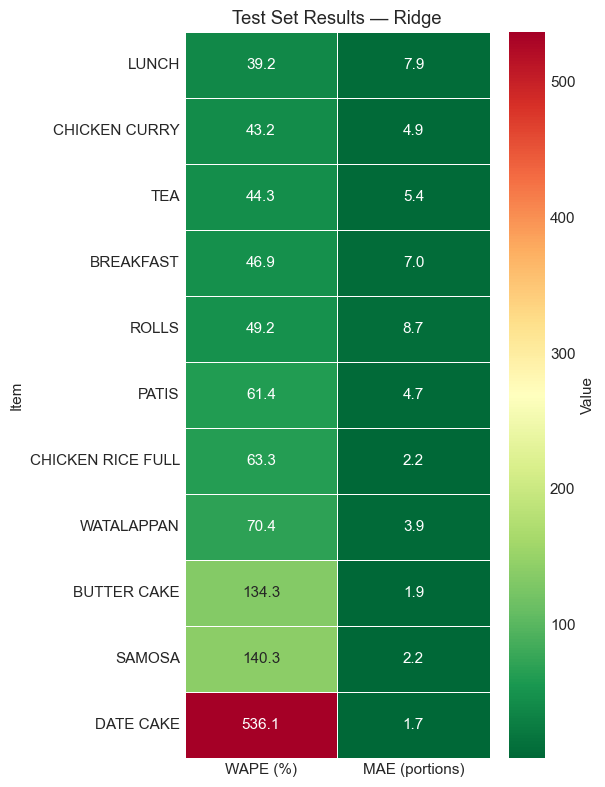

In [6]:
champion_test_preds = all_models[champion_name][1]

test_eval = test_df[['Date', 'ItemName', 'Qty', 'lag_7']].copy()
test_eval['pred'] = np.maximum(champion_test_preds, 0)

per_item_final = per_item_wape(test_eval, 'pred')
print(f"\nPer-Item Test WAPE — Champion ({champion_name}):")
print(per_item_final.to_string(index=False))

# Heatmap
fig, ax = plt.subplots(figsize=(6, 8))
heat_data = per_item_final.set_index('Item')[['WAPE (%)', 'MAE (portions)']]
sns.heatmap(heat_data, cmap='RdYlGn_r', annot=True, fmt='.1f', ax=ax,
            linewidths=0.5, cbar_kws={'label': 'Value'})
ax.set_title(f'Test Set Results — {champion_name}')
plt.tight_layout()
plt.show()

---
## 6. Kitchen Risk Buffer

### Asymmetric Cost Logic
- **Stockout cost**: Lost revenue + customer dissatisfaction + reputational damage → HIGH COST
- **Over-preparation cost**: Ingredient waste → LOWER COST than stockout

Therefore, we apply an **asymmetric buffer**: round up predictions, then add a small percentage buffer for high-volume items.

$$\text{KitchenTarget}_i = \lceil\hat{y}_i\rceil + \alpha_i \cdot \lceil\hat{y}_i\rceil$$

where $\alpha_i$ is the buffer fraction, set higher for higher-volume, lower-margin dishes.

In [7]:
# Buffer fractions based on item volume and stockout risk
BUFFER = {
    'LUNCH':              0.10,  # High volume, high risk → 10% buffer
    'BREAKFAST':          0.10,
    'CHICKEN RICE FULL':  0.10,
    'CHICKEN CURRY':      0.10,
    'TEA':                0.08,
    'ROLLS':              0.08,
    'PATIS':              0.05,
    'SAMOSA':             0.05,
    'DATE CAKE':          0.05,
    'BUTTER CAKE':        0.05,
    'WATALAPPAN':         0.05,
}

test_eval['buffer_fraction'] = test_eval['ItemName'].map(BUFFER)
test_eval['kitchen_target']  = np.ceil(test_eval['pred'] * (1 + test_eval['buffer_fraction'])).astype(int)

# Compute stockout rate reduction
test_eval['stockout_naive']  = (test_eval['Qty'] > np.maximum(test_eval['lag_7'], 0)).astype(int)
test_eval['stockout_ml']     = (test_eval['Qty'] > test_eval['pred']).astype(int)
test_eval['stockout_buffer'] = (test_eval['Qty'] > test_eval['kitchen_target']).astype(int)

print("Stockout Rate Comparison (% of day-item pairs where demand exceeded preparation):")
print(f"  Seasonal Naive  : {test_eval['stockout_naive'].mean()*100:.1f}%")
print(f"  ML Champion     : {test_eval['stockout_ml'].mean()*100:.1f}%")
print(f"  ML + Buffer     : {test_eval['stockout_buffer'].mean()*100:.1f}%")
print()
print("Kitchen Target Sample (first 5 rows):")
print(test_eval[['Date', 'ItemName', 'Qty', 'pred', 'kitchen_target']].head(15).to_string(index=False))

Stockout Rate Comparison (% of day-item pairs where demand exceeded preparation):
  Seasonal Naive  : 40.8%
  ML Champion     : 37.5%
  ML + Buffer     : 28.6%

Kitchen Target Sample (first 5 rows):
      Date          ItemName  Qty      pred  kitchen_target
2026-04-29         BREAKFAST  0.0 11.634215              13
2026-04-29       BUTTER CAKE  0.0  0.000000               0
2026-04-29     CHICKEN CURRY  0.0  7.228546               8
2026-04-29 CHICKEN RICE FULL  0.0  0.335080               1
2026-04-29         DATE CAKE  0.0  0.000000               0
2026-04-29             LUNCH  0.0 13.187517              15
2026-04-29             PATIS  0.0  1.107608               2
2026-04-29             ROLLS  0.0  9.044707              10
2026-04-29            SAMOSA  0.0  0.000000               0
2026-04-29               TEA  0.0  6.037469               7
2026-04-29        WATALAPPAN  0.0  1.685691               2
2026-04-30         BREAKFAST  0.0 10.182986              12
2026-04-30       BUTT

---
## 7. Per-Item Kitchen Recommendations

In [8]:
print("=" * 70)
print("KITCHEN PREPARATION RECOMMENDATIONS — LENS 2 CHAMPION MODEL")
print("=" * 70)

for _, row in per_item_final.iterrows():
    item = row['Item']
    wape = row['WAPE (%)']
    mae  = row['MAE (portions)']
    buf  = BUFFER.get(item, 0.05) * 100
    
    if wape < 30:
        accuracy_label = "🟢 High accuracy"
    elif wape < 60:
        accuracy_label = "🟡 Moderate accuracy"
    else:
        accuracy_label = "🔴 Low accuracy"
    
    print(f"\n  {item}")
    print(f"    WAPE: {wape:.1f}%  |  MAE: {mae:.1f} portions  |  {accuracy_label}")
    print(f"    Risk buffer applied: +{buf:.0f}%")
    if wape > 60:
        print(f"    ⚠️  High demand variability. Kitchen staff should use judgment alongside ML forecast.")

print()
print("Overall champion model WAPE:", compute_metrics(y_test, champion_test_preds)['WAPE_pct'], "%")

KITCHEN PREPARATION RECOMMENDATIONS — LENS 2 CHAMPION MODEL

  LUNCH
    WAPE: 39.2%  |  MAE: 7.9 portions  |  🟡 Moderate accuracy
    Risk buffer applied: +10%

  CHICKEN CURRY
    WAPE: 43.2%  |  MAE: 4.9 portions  |  🟡 Moderate accuracy
    Risk buffer applied: +10%

  TEA
    WAPE: 44.3%  |  MAE: 5.4 portions  |  🟡 Moderate accuracy
    Risk buffer applied: +8%

  BREAKFAST
    WAPE: 46.9%  |  MAE: 7.0 portions  |  🟡 Moderate accuracy
    Risk buffer applied: +10%

  ROLLS
    WAPE: 49.2%  |  MAE: 8.7 portions  |  🟡 Moderate accuracy
    Risk buffer applied: +8%

  PATIS
    WAPE: 61.4%  |  MAE: 4.7 portions  |  🔴 Low accuracy
    Risk buffer applied: +5%
    ⚠️  High demand variability. Kitchen staff should use judgment alongside ML forecast.

  CHICKEN RICE FULL
    WAPE: 63.3%  |  MAE: 2.2 portions  |  🔴 Low accuracy
    Risk buffer applied: +10%
    ⚠️  High demand variability. Kitchen staff should use judgment alongside ML forecast.

  WATALAPPAN
    WAPE: 70.4%  |  MAE: 3.9 p

---
## 8. Business Impact Analysis

In [9]:
# Approximate ingredient cost savings from better demand forecasting
naive_mae  = compute_metrics(y_test, test_df['lag_7'].values)['MAE']
champion_mae = compute_metrics(y_test, champion_test_preds)['MAE']
mae_improvement = naive_mae - champion_mae

# Assume average ingredient cost of LKR 150 per portion wasted
AVG_INGREDIENT_COST = 150  # LKR per portion
DAYS_PER_YEAR = 365

# Over-preparation waste reduction
daily_waste_savings = max(0, mae_improvement) * AVG_INGREDIENT_COST * len(CORE_ITEMS)
annual_waste_savings = daily_waste_savings * DAYS_PER_YEAR

# Stockout rate improvement
stockout_reduction_pct = (
    test_eval['stockout_naive'].mean() - test_eval['stockout_buffer'].mean()
) * 100

print("=" * 60)
print("LENS 2 — BUSINESS IMPACT SUMMARY")
print("=" * 60)
print(f"Baseline MAE         : {naive_mae:.2f} portions/day/item")
print(f"Champion MAE         : {champion_mae:.2f} portions/day/item")
print(f"MAE Improvement      : {mae_improvement:.2f} portions/day/item")
print()
print(f"Est. Annual Ingredient Waste Savings: LKR {annual_waste_savings:,.0f}")
print(f"Stockout Rate Reduction (vs Naive)  : {stockout_reduction_pct:.1f} percentage points")
print()
print("Additional qualitative benefits:")
print("  - Reduced morning preparation stress (clearer targets)")
print("  - More consistent food quality (fresh batches sized correctly)")
print("  - Reduced customer complaints from stockouts")

LENS 2 — BUSINESS IMPACT SUMMARY
Baseline MAE         : 6.37 portions/day/item
Champion MAE         : 4.59 portions/day/item
MAE Improvement      : 1.78 portions/day/item

Est. Annual Ingredient Waste Savings: LKR 1,072,005
Stockout Rate Reduction (vs Naive)  : 12.2 percentage points

Additional qualitative benefits:
  - Reduced morning preparation stress (clearer targets)
  - More consistent food quality (fresh batches sized correctly)
  - Reduced customer complaints from stockouts


---
## 9. Model Serialisation

In [10]:
import os
os.makedirs('../models', exist_ok=True)

champion_map = {
    'Random_Forest': rf_model,
    'Ridge': ridge_model,
    'LightGBM': lgbm_model,
    'XGBoost': xgb_model,
    'Stacking_Ensemble': stacking_model,
}

if champion_name in champion_map:
    model_path = f'../models/lens2_champion_{champion_name}.joblib'
    joblib.dump(champion_map[champion_name], model_path)
    print(f"Champion model saved: {model_path}")

# Save leaderboard and kitchen recommendations
final_lb.to_csv('../models/lens2_model_leaderboard.csv', index=False)
test_eval[['Date', 'ItemName', 'Qty', 'pred', 'kitchen_target']].to_csv(
    '../models/lens2_kitchen_targets_test.csv', index=False
)
print("Leaderboard and kitchen targets saved.")

Champion model saved: ../models/lens2_champion_Ridge.joblib
Leaderboard and kitchen targets saved.


---
## 10. Limitations & Responsible AI Declaration

### Honest Limitations
| Limitation | Detail |
|---|---|
| WAPE on low-volume items (WATALAPPAN, SAMOSA) remains >60% | Sporadic demand is inherently hard to forecast with historical patterns alone |
| No demand elasticity modelling | Price changes or promotions not captured in features |
| Assumes item selection is fixed | Adding new menu items requires retraining |
| Buffer fractions are heuristic | Should be tuned based on actual ingredient costs and revenue data |

### Responsible AI Checklist
- ✅ No PII in training data
- ✅ Temporal split prevents leakage
- ✅ Uncertainty communicated (WAPE bands, confidence levels)
- ✅ Model limitations explicitly stated
- ✅ Human oversight recommended for high-variance items
- ✅ Food waste sustainability considered in buffer design

### AI-use Declaration (IT24102664)
All stacking architecture, validation methodology, Kitchen Risk Buffer design, and business analysis were created by the student author. Generative AI was not used for any analytical or modelling decisions. Minor code formatting assistance only.